### Big 5 Leauges Statistics 2026/2027 

In [5]:
import pandas as pd
import undetected_chromedriver as uc
import lxml
from io import StringIO
import html5lib
import matplotlib.pyplot as plt
from tabulate import tabulate

In [6]:
# initialize the undetected Chrome driver
driver = uc.Chrome()

# navigate to the URL
driver.get("https://fbref.com/en/comps/Big5/Big-5-European-Leagues-Stats")

In [8]:
big_5_table_raw_df = pd.read_html(
    StringIO(driver.page_source),
    attrs={"id": "big5_table"},
)[0]

big_5_table_raw_df.head()


,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Top Team Scorer,Goalkeeper
0,1,Barcelona,es ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Raphinha - 15,Joan García
1,2,Arsenal,eng ENG,1,10,9,0,1,15,5,+10,27,2.70,W W W W W,60229,"Martin Ødegaard, Kai Havertz... - 3",David Raya
2,3,Lazio,it ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,"Davide Frattesi, Gustav Isaksen... - 4",Christos Mandas
3,4,Inter,it ITA,2,11,9,1,1,28,13,+15,28,2.55,W W W L W,75214,Marcus Thuram - 6,Josep Martinez
4,5,Real Madrid,es ESP,2,12,10,0,2,31,10,+21,30,2.50,W W W W W,73614,Kylian Mbappé - 13,Thibaut Courtois


In [9]:
# Remove rows where 'GF' is 'GF' and 'Pts' is 'Pts'
big_5_table_df = big_5_table_raw_df[
    ~((big_5_table_raw_df['GF'] == 'GF') & (big_5_table_raw_df['Pts'] == 'Pts'))
]

big_5_table_df.head()

,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Top Team Scorer,Goalkeeper
0,1,Barcelona,es ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Raphinha - 15,Joan García
1,2,Arsenal,eng ENG,1,10,9,0,1,15,5,+10,27,2.70,W W W W W,60229,"Martin Ødegaard, Kai Havertz... - 3",David Raya
2,3,Lazio,it ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,"Davide Frattesi, Gustav Isaksen... - 4",Christos Mandas
3,4,Inter,it ITA,2,11,9,1,1,28,13,+15,28,2.55,W W W L W,75214,Marcus Thuram - 6,Josep Martinez
4,5,Real Madrid,es ESP,2,12,10,0,2,31,10,+21,30,2.50,W W W W W,73614,Kylian Mbappé - 13,Thibaut Courtois


In [42]:
# Clean the DataFrame by converting the data types of the columns to the appropriate types
big_5_table_df_clean = big_5_table_df.astype({
    'GF': 'int',
    'GA': 'int',
    'Pts': 'int',
    'W': 'int',
    'D': 'int',
    'L': 'int',
    'Country': 'str',
    'MP': 'int',
    'Pts/MP': 'float',
    'MP': 'int',
    'Attendance': 'int'
})


big_5_table_df_clean.head(3)

,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Top Team Scorer,Goalkeeper
0,1,Barcelona,es ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Raphinha - 15,Joan García
1,2,Arsenal,eng ENG,1,10,9,0,1,15,5,+10,27,2.70,W W W W W,60229,"Martin Ødegaard, Kai Havertz... - 3",David Raya
2,3,Lazio,it ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,"Davide Frattesi, Gustav Isaksen... - 4",Christos Mandas


In [43]:
big_5_table_df_clean.dtypes

Rk                     str
Squad                  str
Country                str
LgRk                   str
MP                   int64
W                    int64
D                    int64
L                    int64
GF                   int64
GA                   int64
GD                     str
Pts                  int64
Pts/MP             float64
Last 5                 str
Attendance           int64
Top Team Scorer        str
Goalkeeper             str
dtype: object

In [13]:
# apply the following transformations to the DataFrame
big_5_table_df_clean['Country'] = big_5_table_df_clean['Country'].str.split(' ').str[-1]
big_5_table_df_clean['Top Team Scorer Player'] = big_5_table_df_clean['Top Team Scorer'].str.split('-').str[0]
big_5_table_df_clean['Top Team Scorer Goals'] = big_5_table_df_clean['Top Team Scorer'].str.split('-').str[-1]
big_5_table_df_clean = big_5_table_df_clean.drop(columns=['Top Team Scorer'])
big_5_table_df_clean.head()


,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Goalkeeper,Top Team Scorer Player,Top Team Scorer Goals
0,1,Barcelona,ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Joan García,Raphinha,15
1,2,Arsenal,ENG,1,10,9,0,1,15,5,+10,27,2.70,W W W W W,60229,David Raya,"Martin Ødegaard, Kai Havertz...",3
2,3,Lazio,ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,Christos Mandas,"Davide Frattesi, Gustav Isaksen...",4
3,4,Inter,ITA,2,11,9,1,1,28,13,+15,28,2.55,W W W L W,75214,Josep Martinez,Marcus Thuram,6
4,5,Real Madrid,ESP,2,12,10,0,2,31,10,+21,30,2.50,W W W W W,73614,Thibaut Courtois,Kylian Mbappé,13


In [14]:
big_5_table_df_clean = big_5_table_df_clean.astype({
    'Top Team Scorer Player': 'str',
    'Top Team Scorer Goals': 'int'
})

big_5_table_df_clean.head(3)



,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Goalkeeper,Top Team Scorer Player,Top Team Scorer Goals
0,1,Barcelona,ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Joan García,Raphinha,15
1,2,Arsenal,ENG,1,10,9,0,1,15,5,+10,27,2.70,W W W W W,60229,David Raya,"Martin Ødegaard, Kai Havertz...",3
2,3,Lazio,ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,Christos Mandas,"Davide Frattesi, Gustav Isaksen...",4


In [20]:
big_5_table_df_clean.columns

Index(['Rk', 'Squad', 'Country', 'LgRk', 'MP', 'W', 'D', 'L', 'GF', 'GA', 'GD',
       'Pts', 'Pts/MP', 'Last 5', 'Attendance', 'Goalkeeper',
       'Top Team Scorer Player', 'Top Team Scorer Goals'],
      dtype='str')

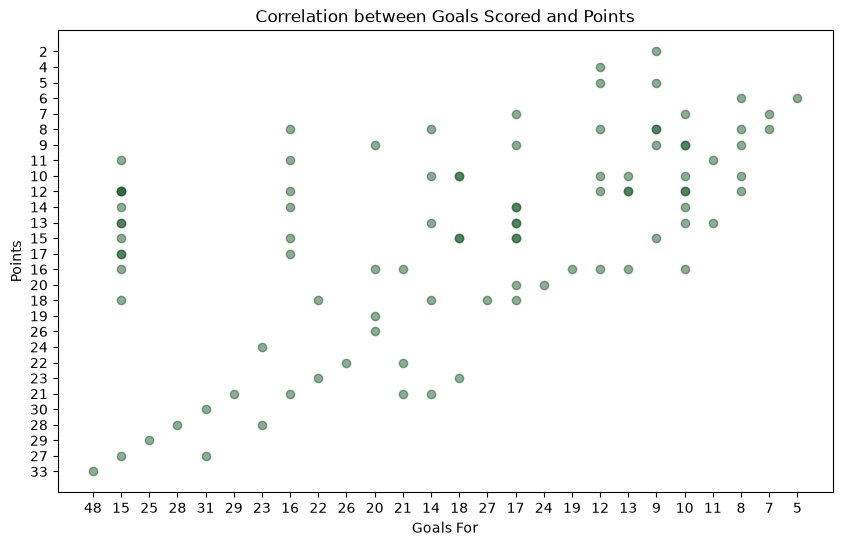

In [15]:
# See the correlation between the goals scored and the points for each team in the Big 5 European Leagues Stats
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(big_5_table_df['GF'], big_5_table_df['Pts'], color='#1A5A2A', alpha=0.5)
ax.set_xlabel('Goals For')
ax.set_ylabel('Points')
ax.set_title('Correlation between Goals Scored and Points')

plt.show()

##### La Lega Espania is the top league of the most goals scored in this season till now

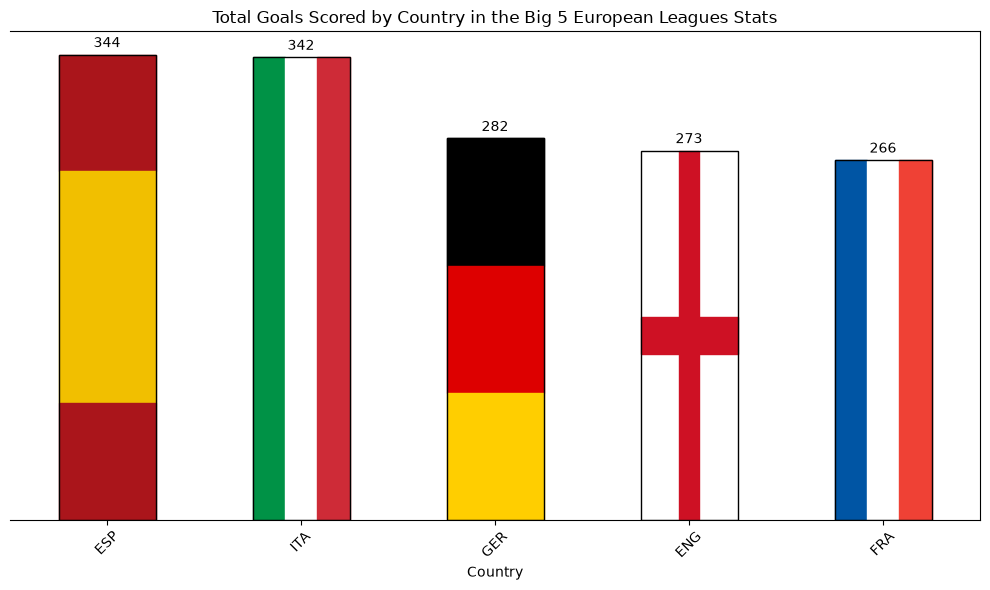

In [17]:
from matplotlib.patches import Rectangle

total_goals_by_country = big_5_table_df_clean.groupby('Country')['GF'].sum().sort_values(ascending=False)

# Map whatever is in your Country column (codes or names) to a flag
ALIASES = {
    'ENG': 'England', 'ENGLAND': 'England',
    'ESP': 'Spain',   'SPAIN': 'Spain',
    'ITA': 'Italy',   'ITALY': 'Italy',
    'GER': 'Germany', 'DEU': 'Germany', 'GERMANY': 'Germany',
    'FRA': 'France',  'FRANCE': 'France',
}

# (direction, [(color, relative size), ...])
FLAGS = {
    'Spain':   ('h', [('#AA151B', 1), ('#F1BF00', 2), ('#AA151B', 1)]),
    'Germany': ('h', [('#000000', 1), ('#DD0000', 1), ('#FFCE00', 1)]),
    'Italy':   ('v', [('#009246', 1), ('#FFFFFF', 1), ('#CE2B37', 1)]),
    'France':  ('v', [('#0055A4', 1), ('#FFFFFF', 1), ('#EF4135', 1)]),
}

def draw_flag(ax, bar, country):
    x, w, h = bar.get_x(), bar.get_width(), bar.get_height()
    name = ALIASES.get(str(country).split()[-1].upper())

    if name == 'England':
        ax.add_patch(Rectangle((x, 0), w, h, color='white', zorder=2))
        ax.add_patch(Rectangle((x + w * 0.4, 0), w * 0.2, h, color='#CE1124', zorder=3))   # vertical arm
        ax.add_patch(Rectangle((x, h * 0.5 - h * 0.05), w, h * 0.10, color='#CE1124', zorder=3))  # horizontal arm
    elif name in FLAGS:
        direction, stripes = FLAGS[name]
        total = sum(size for _, size in stripes)
        pos = 0
        for color, size in stripes:
            frac = size / total
            if direction == 'h':  # stripes stacked top to bottom
                ax.add_patch(Rectangle((x, h * (1 - pos - frac)), w, h * frac, color=color, zorder=2))
            else:                 # stripes left to right
                ax.add_patch(Rectangle((x + w * pos, 0), w * frac, h, color=color, zorder=2))
            pos += frac
    else:
        ax.add_patch(Rectangle((x, 0), w, h, color='#999999', zorder=2))  # unknown country

fig, ax = plt.subplots(figsize=(10, 6))
total_goals_by_country.plot(kind='bar', color='none', edgecolor='black', linewidth=1, ax=ax, zorder=4)

for bar, country in zip(ax.containers[0], total_goals_by_country.index):
    draw_flag(ax, bar, country)

ax.bar_label(ax.containers[0], padding=3)
ax.get_yaxis().set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('Country')
ax.set_title('Total Goals Scored by Country in the Big 5 European Leagues Stats')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### The Top 10 Clubs with attendance per match this season only for the home matches
```
 - Dortmund in the Top 
 - Manchester United is the only team from the Premier League, despite their poor results, and 3 Clubs from Bundesleaga, La Liga and Serie A
```

In [44]:
big_5_table_df_clean['Attendance'].astype('int')
top10_clubs_attendance = big_5_table_df_clean[['Squad', 'Attendance']].sort_values('Attendance', ascending=False).head(10)
top10_clubs_attendance

,Squad,Attendance
8,Dortmund,81365
3,Inter,75214
6,Bayern Munich,75000
11,Milan,74545
82,Manchester Utd,74153
4,Real Madrid,73614
7,Atlético Madrid,66268
5,Roma,65759
12,Real Betis,63309
92,Schalke 04,61870


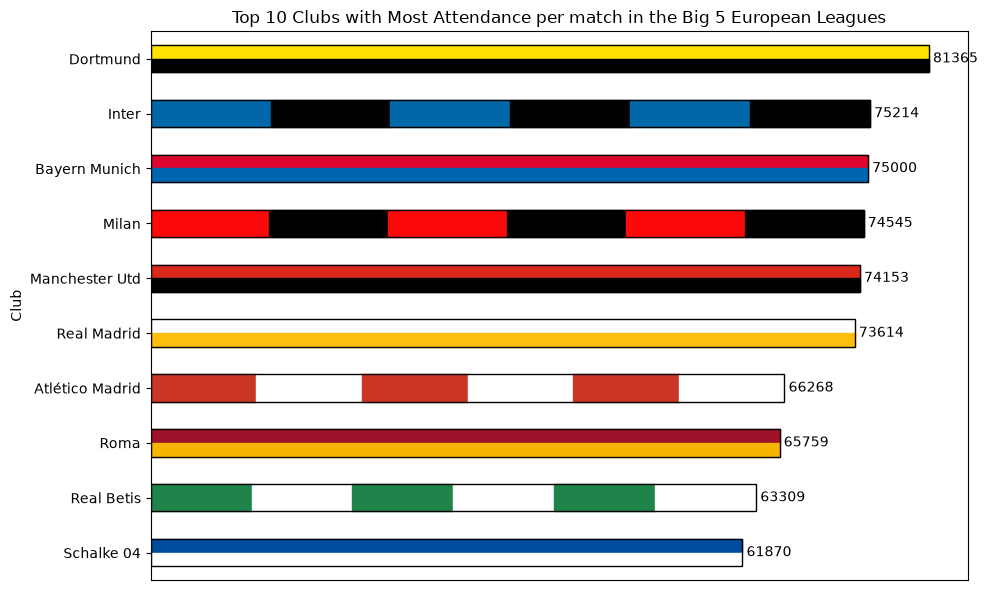

In [46]:
top10_clubs_attendance = big_5_table_df_clean[['Squad', 'Attendance']].sort_values('Attendance', ascending=False).head(10)
top10_clubs_attendance['Attendance']

# keyword (lowercase, matched as a substring of the squad name) -> (style, colors)
# 'h' = bands stacked along the bar's length, 'v' = blocks left to right
CLUB_COLORS = {
    'dortmund':    ('h', ['#FDE100', '#000000']),
    'bayern':      ('h', ['#DC052D', '#0066B2']),
    'manchester utd': ('h', ['#DA291C', '#000000']),
    'real madrid': ('h', ['#FFFFFF', '#FEBE10']),
    'atl':         ('v', ['#CB3524', '#FFFFFF'] * 3),   # Atlético Madrid
    'milan':       ('v', ['#FB090B', '#000000'] * 3),
    'inter':       ('v', ['#0068A8', '#000000'] * 3),
    'schalke':     ('h', ['#004D9D', '#FFFFFF']),
    'real betis':    ('v', ['#1E8449', '#FFFFFF'] * 3),
    'roma':        ('h', ['#9D1229', '#F7B500']),
}

def get_style(squad):
    s = str(squad).lower()
    for key, style in CLUB_COLORS.items():
        if key in s:
            return style
    return ('h', ['#999999'])  # unknown club -> grey

def draw_club(ax, bar, squad):
    x, y = bar.get_x(), bar.get_y()
    w, h = bar.get_width(), bar.get_height()
    direction, colors = get_style(squad)
    n = len(colors)
    for i, color in enumerate(colors):
        if direction == 'h':   # bands along the bar
            ax.add_patch(Rectangle((x, y + h * i / n), w, h / n, color=color, zorder=2))
        else:                  # blocks left to right
            ax.add_patch(Rectangle((x + w * i / n, y), w / n, h, color=color, zorder=2))

fig, ax = plt.subplots(figsize=(10, 6))

top10_clubs_attendance.plot(
    kind='barh',
    x='Squad',
    y='Attendance',
    color='none',
    edgecolor='black',
    linewidth=1,
    ax=ax,
    legend=False,
    zorder=4
)

for bar, squad in zip(ax.containers[0], top10_clubs_attendance['Squad']):
    draw_club(ax, bar, squad)

ax.bar_label(ax.containers[0], padding=3)
ax.get_xaxis().set_visible(False)
ax.set_ylabel('Club')
ax.set_title('Top 10 Clubs with Most Attendance per match in the Big 5 European Leagues')
ax.invert_yaxis()

plt.tight_layout()
plt.show()

[None, None, None, None, None]

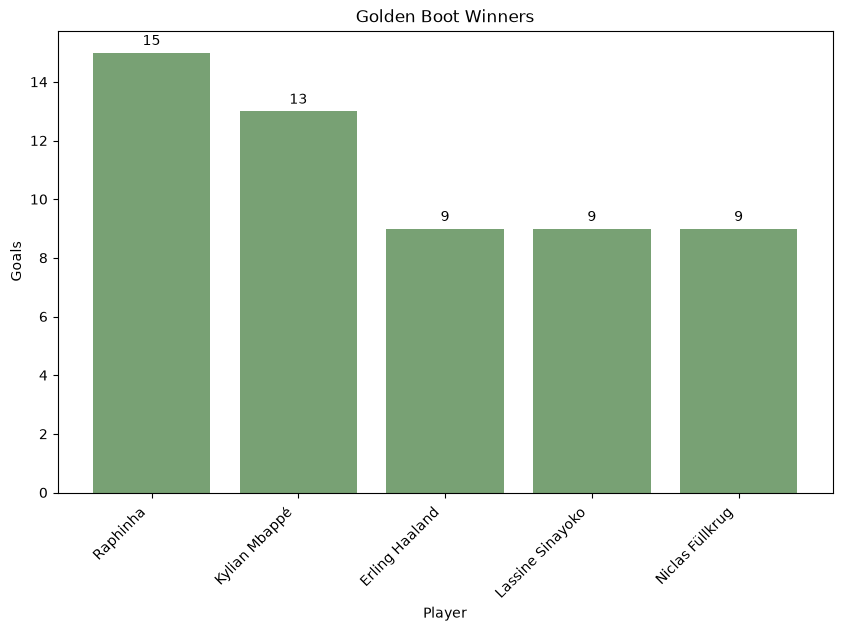

In [19]:
# The Golden Boot is an award given to the top goal scorer in European leagues. 
# The award is based on a points system that takes into account the number of goals scored and the difficulty of the league 
# in which the player competes. The player with the highest number of points at the end of the season is awarded the Golden Boot.
golden_boot_df = big_5_table_df_clean.sort_values(
    'Top Team Scorer Goals', ascending=False
).head(5).copy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    golden_boot_df['Top Team Scorer Player'],
    golden_boot_df['Top Team Scorer Goals'],
    color='#3F7A39',
    alpha=0.7
)

ax.set_xlabel('Player')
ax.set_ylabel('Goals')
ax.set_title('Golden Boot Winners')
ax.bar_label(ax.containers[0], padding=3)
ax.tick_params(axis='x', labelrotation=45)
plt.setp(ax.get_xticklabels(), ha='right')



In [ ]:
big_5_table_df_clean.to_csv('big_5_Leagues_Stats_20-27.csv', index=False)

In [47]:
clubs_gd_sorted = (
    big_5_table_df_clean
    .assign(_GD=big_5_table_df_clean['GF'] - big_5_table_df_clean['GA'])
    .sort_values('_GD', ascending=False)
    .drop(columns='_GD')
)

clubs_gd_sorted.head(10)

,Rk,Squad,Country,LgRk,MP,W,D,L,GF,GA,GD,Pts,Pts/MP,Last 5,Attendance,Top Team Scorer,Goalkeeper
0,1,Barcelona,es ESP,1,12,11,0,1,48,13,+35,33,2.75,W W L W W,57118,Raphinha - 15,Joan García
4,5,Real Madrid,es ESP,2,12,10,0,2,31,10,+21,30,2.50,W W W W W,73614,Kylian Mbappé - 13,Thibaut Courtois
5,6,Roma,it ITA,3,11,8,3,0,31,10,+21,27,2.45,W D W W W,65759,Donyell Malen - 8,"Pierluigi Gollini, Mile Svilar"
6,7,Bayern Munich,de GER,1,9,6,3,0,29,9,+20,21,2.33,D W W D W,75000,Michael Olise - 6,Jonas Urbig
10,11,Brighton,eng ENG,2,10,7,1,2,26,7,+19,22,2.20,W W L W W,31684,Pascal Groß - 4,Bart Verbruggen
2,3,Lazio,it ITA,1,11,9,2,0,25,9,+16,29,2.64,W W W W D,10141,"Davide Frattesi, Gustav Isaksen... - 4",Christos Mandas
3,4,Inter,it ITA,2,11,9,1,1,28,13,+15,28,2.55,W W W L W,75214,Marcus Thuram - 6,Josep Martinez
17,18,RB Leipzig,de GER,4,9,6,0,3,27,13,+14,18,2.00,W L W W W,44564,"Christopher Nkunku, Rômulo - 5",Maarten Vandevoordt
7,8,Atlético Madrid,es ESP,3,12,9,1,2,23,10,+13,28,2.33,W W W W L,66268,Álex Baena - 5,Jan Oblak
9,10,Paris SG,fr FRA,1,10,7,2,1,22,10,+12,23,2.30,W W W W W,47651,Ferran Torres - 4,Matvei Safonov


In [48]:
top10_GD_teams = clubs_gd_sorted[['Squad', 'GF', 'GA', 'GD', 'Pts']].head(10)
top10_GD_teams

,Squad,GF,GA,GD,Pts
0,Barcelona,48,13,+35,33
4,Real Madrid,31,10,+21,30
5,Roma,31,10,+21,27
6,Bayern Munich,29,9,+20,21
10,Brighton,26,7,+19,22
2,Lazio,25,9,+16,29
3,Inter,28,13,+15,28
17,RB Leipzig,27,13,+14,18
7,Atlético Madrid,23,10,+13,28
9,Paris SG,22,10,+12,23


In [49]:
top10_GD_teams_table = tabulate(
    top10_GD_teams,
    headers='keys',
    tablefmt='pretty',
    showindex=False
)
print(top10_GD_teams_table)

+-----------------+----+----+-----+-----+
|      Squad      | GF | GA | GD  | Pts |
+-----------------+----+----+-----+-----+
|    Barcelona    | 48 | 13 | +35 | 33  |
|   Real Madrid   | 31 | 10 | +21 | 30  |
|      Roma       | 31 | 10 | +21 | 27  |
|  Bayern Munich  | 29 | 9  | +20 | 21  |
|    Brighton     | 26 | 7  | +19 | 22  |
|      Lazio      | 25 | 9  | +16 | 29  |
|      Inter      | 28 | 13 | +15 | 28  |
|   RB Leipzig    | 27 | 13 | +14 | 18  |
| Atlético Madrid | 23 | 10 | +13 | 28  |
|    Paris SG     | 22 | 10 | +12 | 23  |
+-----------------+----+----+-----+-----+


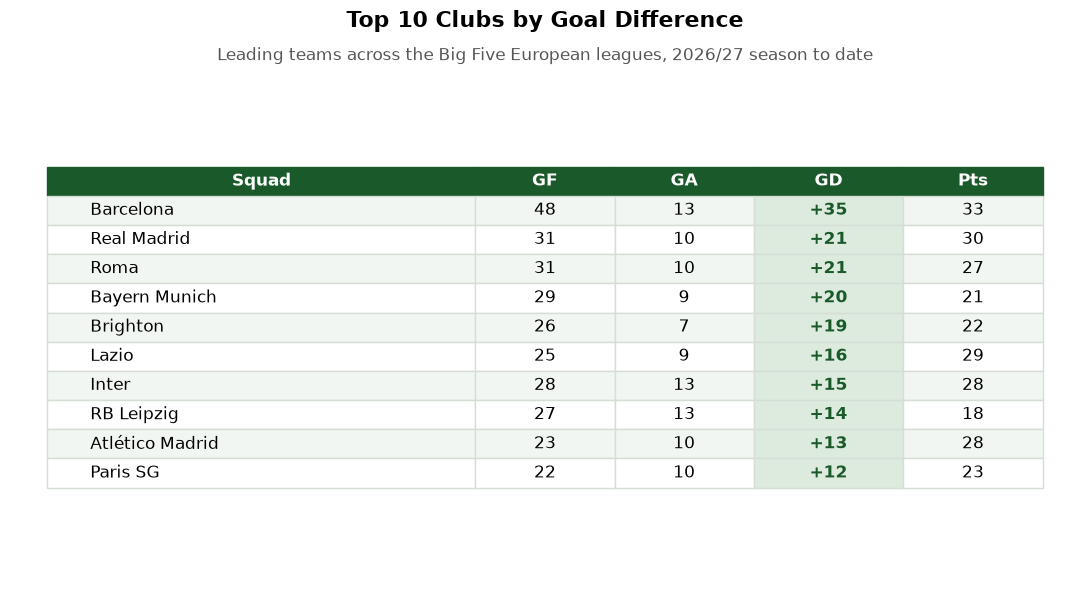

In [50]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.axis('off')

row_colors = ['#F2F6F2' if i % 2 == 0 else 'white' for i in range(len(top10_GD_teams))]
cell_colors = [[color] * len(top10_GD_teams.columns) for color in row_colors]

table = ax.table(
    cellText=top10_GD_teams.values,
    colLabels=top10_GD_teams.columns,
    cellColours=cell_colors,
    colColours=['#1A5A2A'] * len(top10_GD_teams.columns),
    colWidths=[0.40, 0.13, 0.13, 0.14, 0.13],
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.6)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#D5DED5')
    if row == 0:
        cell.set_text_props(color='white', weight='bold')
        cell.set_edgecolor('#1A5A2A')
    elif col == 0:
        cell.set_text_props(ha='left')
    elif col == 3:  # Emphasize goal difference
        cell.set_facecolor('#DCEBDD')
        cell.set_text_props(weight='bold', color='#1A5A2A')

ax.set_title('Top 10 Clubs by Goal Difference', fontsize=16, weight='bold', pad=34)
ax.text(
    0.5, 1.02,
    'Leading teams across the Big Five European leagues, 2026/27 season to date',
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=12,
    color='#555555'
)

fig.tight_layout()
plt.show()